a title for your project and a short section at the beginning summarizing the findings.

For this assignment, you will practice using some of the machine learning methods we have used in class so far. We will be working with the Iris dataset, which contains information about
different flower characteristics. You can download the data here.
https://archive.ics.uci.edu/dataset/53/iris
Your goal is to predict the “class” label.
1. Start off with a description of the dataset. How many rows are there? How many features? What is the proportion of observations in each class?

1. support vector machines (SVMs) 
2. random forests 13
3. neural networks 14 
4. and at least one method we have not covered in class (lasso, naïve bayes, ridge, etc.)
5. Evaluate the predictive performance using cross-validation. Consider more than one evaluation metric.
o Use the default tuning parameters for all methods except one (you choose). For this method, define a grid of tuning parameters and select the best-performing ones.

Compute an additional table/figure not included in the questions above.
4. What do we learn from it?
Make sure to properly document your approach. Give a recommendation about which method
you think predicts the class labels best

In [31]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [32]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo 

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing
from sklearn.metrics import get_scorer_names

# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
  
# fetch dataset 
iris = fetch_ucirepo(id=53) 
  
# data (as pandas dataframes) 
X = iris.data.features 
y = iris.data.targets 
  
# metadata 
print(iris.metadata) 
  
# variable information 
print(iris.variables) 


{'uci_id': 53, 'name': 'Iris', 'repository_url': 'https://archive.ics.uci.edu/dataset/53/iris', 'data_url': 'https://archive.ics.uci.edu/static/public/53/data.csv', 'abstract': 'A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification methods.\n', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 150, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1936, 'last_updated': 'Tue Sep 12 2023', 'dataset_doi': '10.24432/C56C76', 'creators': ['R. A. Fisher'], 'intro_paper': {'ID': 191, 'type': 'NATIVE', 'title': 'The Iris data set: In search of the source of virginica', 'authors': 'A. Unwin, K. Kleinman', 'venue': 'Significance, 2021', 'year': 2021, 'journal': 'Significance, 2021', 'DOI': '1740-9713.01589', 'URL': 'https://www.semanticscholar.org

1. Start off with a description of the dataset. How many rows are there? How many features? What is the proportion of observations in each class?

In [33]:

import pandas as pd

iris = fetch_ucirepo(id=53)
X = iris.data.features
y = iris.data.targets["class"]  

# Rows and features
print(len(X))       
print(X.shape[1])   

# Proportion of observations in each class 
table_y = pd.crosstab(y, "proportion") / len(y)
display(table_y)
print(summary)

150
4


col_0,proportion
class,
Iris-setosa,0.333333
Iris-versicolor,0.333333
Iris-virginica,0.333333


                 count  proportion    percent
class                                        
Iris-setosa         50    0.333333  33.333333
Iris-versicolor     50    0.333333  33.333333
Iris-virginica      50    0.333333  33.333333


In [ ]:
table_y = pd.crosstab(y, "proportion") / len(y)

# Rename the axes and make the index a regular column
table_pretty = table_y.rename_axis(index="Species", columns=None).reset_index()

table_pretty.style.format({
    "proportion": "{:.1%}"      # shows 33.3% instead of 0.333333
}).hide(axis="index").set_caption("Proportion of observations by class")

Species,proportion
Iris-setosa,33.3%
Iris-versicolor,33.3%
Iris-virginica,33.3%


There are 150 rows, 4 features, and each of the 3 classes make up 33% of the observations.

support vector machines (SVMs) to predict class label

In [35]:
iris = fetch_ucirepo(id=53)
X = iris.data.features
y = iris.data.targets["class"]

# 1. Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                   random_state=104,
                                   test_size=0.25,
                                   shuffle=True) 

# 2. Scale the features
scaler_train = preprocessing.StandardScaler().fit(X_train)
scaler_test  = preprocessing.StandardScaler().fit(X_test)
X_train_scale = scaler_train.transform(X_train)
X_test_scale  = scaler_test.transform(X_test)

# 3. Fit the SVM on the training data
svm = SVC()
svm.fit(X_train_scale, y_train)

# 4. Predict class labels for the test data
predictions = svm.predict(X_test_scale)
print(predictions)

['Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-versicolor'
 'Iris-virginica' 'Iris-virginica' 'Iris-virginica' 'Iris-virginica'
 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa' 'Iris-versicolor'
 'Iris-versicolor' 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-virginica' 'Iris-virginica' 'Iris-setosa'
 'Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-versicolor'
 'Iris-virginica' 'Iris-setosa' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-setosa']


Since the accuracy is only 81%

In [36]:
predictions = svm.predict(X_test_scale)
svm = SVC()
svm.fit(X_train_scale, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


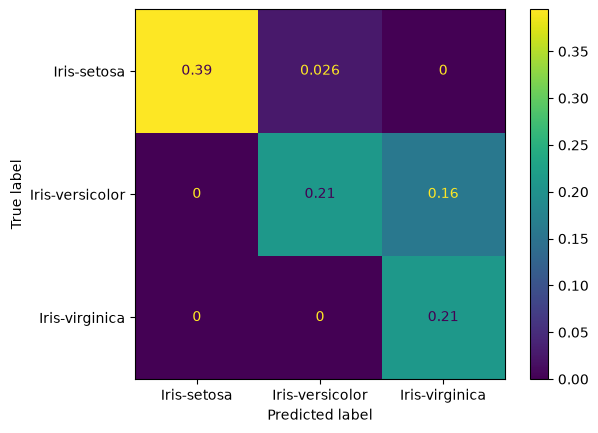

In [37]:
# Compute confusion matrix
cm = confusion_matrix(y_test, predictions, labels=svm.classes_) / len(y_test)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=svm.classes_)
disp.plot()
plt.show()

In [38]:
svm.score(X_test_scale, y_test)

0.8157894736842105

In [39]:
# The "pandas" library is used for processing datasets
# The "numpy" is for numeric observations and random numbers
# The "matplotlib.pyplot" library is for creating graphs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# We will use the "sklearn" package

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn import tree
import sklearn.model_selection as skm
from sklearn.ensemble import RandomForestRegressor as RF
from sklearn.ensemble import GradientBoostingRegressor as GBR

# This is used to create data matrices
import patsy

# This is used to visualize regreesion trees
import graphviz

# Import content from the book "Introduction to Statistical Learning"
import ISLP